# Two-candidate election contests: Kalshi and Polymarket

Overview of `kalshi_binary_elections.json` and `polymarket_binary_elections.json`. Each section shows both
platforms together, then each platform on its own. Figures are saved to `figures/` as PNG and PDF.

In [1]:
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)

# Colours and text tokens
GENERAL, PRIMARY = "#2a78d6", "#eb6834"
SURFACE, INK, INK_2, MUTED, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9"
EMPTY_TILE = "#f0efec"
BLUES = LinearSegmentedColormap.from_list(
    "blues", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": INK_2, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False, "figure.dpi": 110,
})


def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=220, bbox_inches="tight")
    fig.savefig(FIGURES / f"{name}.pdf", bbox_inches="tight")


def value_grid(ax, axis="x"):
    ax.grid(axis=axis, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)


def compact(value, _=None):
    for size, suffix in ((1e9, "B"), (1e6, "M"), (1e3, "K")):
        if value >= size:
            return f"{value / size:.3g}{suffix}"
    return f"{value:g}"

## Load

In [2]:
PRIMARY_WORDS = r"nominee|nomination|primary"

# Kalshi: one row per market; a contest is an event with two markets.
k = pd.DataFrame(json.loads(Path("kalshi_binary_elections.json").read_text()))
k["volume"] = pd.to_numeric(k["volume_fp"])
k["close"] = pd.to_datetime(k["close_time"], utc=True, format="mixed")
kalshi = (k.groupby("event_ticker")
          .agg(title=("title", "first"), series=("series_ticker", "first"),
               volume=("volume", "sum"), close=("close", "min"))
          .reset_index().rename(columns={"event_ticker": "contest_id"}))
kalshi["decided"] = kalshi["close"].dt.tz_localize(None).dt.to_period("M")
# 2024 races close when the winner takes office, so use election day as their date.
old_2024 = kalshi["contest_id"].str.match(r"^(PRESPARTY|HOUSE|SENATE|GOVPARTY)[A-Z].*-24$")
kalshi.loc[old_2024, "decided"] = pd.Period("2024-11", "M")
kalshi["platform"] = "Kalshi"

# Polymarket: one row per event; candidate markets exclude the "Other" basket.
rows = []
for event in json.loads(Path("polymarket_binary_elections.json").read_text()):
    baskets = set(event.get("basket_market_ids") or [])
    candidates = [m for m in event["markets"] if str(m["id"]) not in baskets]
    when = event.get("endDate") or event.get("closedTime")
    rows.append({
        "contest_id": str(event["id"]), "title": event["title"].strip(), "series": None,
        "volume": sum(float(m.get("volumeNum") or 0) for m in candidates),
        "decided": pd.to_datetime(when, utc=True).tz_convert(None).to_period("M"),
        "has_basket": bool(baskets),
    })
poly = pd.DataFrame(rows)
poly["platform"] = "Polymarket"

for df in (kalshi, poly):
    df["kind"] = np.where(df["title"].str.contains(PRIMARY_WORDS, case=False), "Primary", "General")
print(f"Kalshi {len(kalshi)} contests · Polymarket {len(poly)} contests")

Kalshi 367 contests · Polymarket 224 contests


In [3]:
NON_US = {
    "Canada": r"Canadian election|Abbotsford|Oshawa|, BC|, ON|, MB|Nanaimo|Victoria Mayoral|North Vancouver",
    "Brazil": r"Espírito Santo|Tocantins|Paraíba|Belo Horizonte|Curitiba|Fortaleza",
    "South Korea": r"Daegu|Daejeon|Sejong|Gwangju|Gyeongsang", "Ghana": r"Ghanaian", "Uruguay": r"Uruguayan",
    "Guyana": r"Guyana", "Malawi": r"Malawian", "Seychelles": r"Seychellois", "Zambia": r"Zambian",
    "Italy": r"Agrigento|Angri|Arezzo|Casalnuovo|Castelfranco|Castrovillari|Cava De|Chieti|Frattamaggiore|Lecco|"
             r"Legnano|Macerata|Molfetta|Ottaviano|Pompei|San Giovanni Rotondo|San Nicola La Strada",
    "France": r"Marseille|Toulouse", "Turkey": r"Istanbul", "North Macedonia": r"North Macedonia",
    "Bosnia and Herzegovina": r"Republika Srpska", "Benin": r"Benin", "Slovakia": r"Bratislava|Trenčín",
    "Australia": r"Mulka|Central Coast|Devonport",
}
STATES = {
    "AL": "Alabama", "AK": "Alaska", "AZ": "Arizona", "AR": "Arkansas", "CA": "California",
    "CO": "Colorado", "CT": "Connecticut", "DE": "Delaware", "DC": "District of Columbia",
    "FL": "Florida", "GA": "Georgia", "HI": "Hawaii", "ID": "Idaho", "IL": "Illinois",
    "IN": "Indiana", "IA": "Iowa", "KS": "Kansas", "KY": "Kentucky", "LA": "Louisiana",
    "ME": "Maine", "MD": "Maryland", "MA": "Massachusetts", "MI": "Michigan", "MN": "Minnesota",
    "MS": "Mississippi", "MO": "Missouri", "MT": "Montana", "NE": "Nebraska", "NV": "Nevada",
    "NH": "New Hampshire", "NJ": "New Jersey", "NM": "New Mexico", "NY": "New York",
    "NC": "North Carolina", "ND": "North Dakota", "OH": "Ohio", "OK": "Oklahoma", "OR": "Oregon",
    "PA": "Pennsylvania", "RI": "Rhode Island", "SC": "South Carolina", "SD": "South Dakota",
    "TN": "Tennessee", "TX": "Texas", "UT": "Utah", "VT": "Vermont", "VA": "Virginia",
    "WA": "Washington", "WV": "West Virginia", "WI": "Wisconsin", "WY": "Wyoming",
}
CITIES = {"Charlotte": "NC", "Cincinnati": "OH", "Cleveland": "OH", "Miami": "FL", "Pittsburgh": "PA",
          "Sioux Falls": "SD", "Ann Arbor": "MI", "NYC": "NY", "Bronx": "NY", "King County": "WA",
          "Worcester": "MA", "Oakland": "CA", "Chandler": "AZ", "Providence": "RI", "Washington DC": "DC"}
TICKER_PATTERNS = [
    r"^(?:PRESPARTY|HOUSE|SENATE|GOVPARTY)([A-Z]{2})", r"^KX([A-Z]{2})PRIMARY", r"^KXSENATE([A-Z]{2})[RD]-",
    r"^KXGOV([A-Z]{2})NOM", r"^KX([A-Z]{2})\d+[RD]-", r"^KXAGNOM([A-Z]{2})[RD]-", r"^KXHOUSERACE-([A-Z]{2})\d",
    r"^KXHOUSE([A-Z]{2})\d", r"^KX([A-Z]{2})(?:SOS|TREAS)",
]
NAMES = sorted(STATES.items(), key=lambda item: -len(item[1]))  # "West Virginia" before "Virginia"
NATIONAL = r"US Presidential Election"


def country_of(title):
    return next((country for country, pattern in NON_US.items() if re.search(pattern, title)), "United States")


def state_of(row):
    for city, code_ in CITIES.items():  # first, so "Washington DC" is not Washington state
        if city in row.title:
            return code_
    found = re.search(r"\b([A-Z]{2})-(?:\d+|AL)\b|^([A-Z]{2}) House", row.title)  # NY-13, SD-AL, PA House
    if found and (found.group(1) or found.group(2)) in STATES:
        return found.group(1) or found.group(2)
    for pattern in TICKER_PATTERNS:
        found = re.match(pattern, row.contest_id)
        if found and found.group(1) in STATES:
            return found.group(1)
    for code_, name in NAMES:
        if re.search(rf"\b{name}\b", row.title):
            return code_
    return "national" if re.search(NATIONAL, row.title) else None


def office_of(row):
    title, cid = row.title, row.contest_id
    rules = [
        ("President", cid.startswith("PRESPARTY") or re.search(r"Presidential Election|^Who will win [A-Z][a-z]+( [A-Z][a-z]+)?\?$", title)),
        ("State legislature", re.search(r"State Senate|State Assembly|House District|House of Representatives District", title)),
        ("US Senate", cid.startswith("SENATE") or re.search(r"\bSenate\b", title)),
        ("US House", cid.startswith("HOUSE") or re.search(r"[A-Z]{2}-(\d+|AL)\b|House race|ongressional", title)),
        ("Governor", cid.startswith("GOVPARTY") or re.search(r"Governor|gubernatorial", title, re.I)),
        ("Courts", re.search(r"Court", title)),
        ("Other statewide", re.search(r"Attorney General|attorney general|Lt\. Gov|Secretary of State|Treasurer|Superintendent|Commissioner|Commission", title)),
        ("Local", re.search(r"[Mm]ayor|City Council|County Executive|Borough President", title)),
    ]
    return next((name for name, hit in rules if hit), "Other")


contests = pd.concat([kalshi, poly], ignore_index=True)
contests["country"] = contests["title"].map(country_of)
us = contests["country"] == "United States"
contests.loc[us, "state"] = contests[us].apply(state_of, axis=1)
contests.loc[us, "office"] = contests[us].apply(office_of, axis=1)
missing = contests[us & contests["state"].isna()]
assert missing.empty, missing[["platform", "contest_id", "title"]]
PLATFORMS = {"Both platforms": contests, "Kalshi": contests[contests.platform == "Kalshi"],
             "Polymarket": contests[contests.platform == "Polymarket"]}
contests.groupby(["platform", "kind"]).size().unstack(fill_value=0)

kind,General,Primary
platform,,
Kalshi,163,204
Polymarket,163,61


## Platforms at a glance

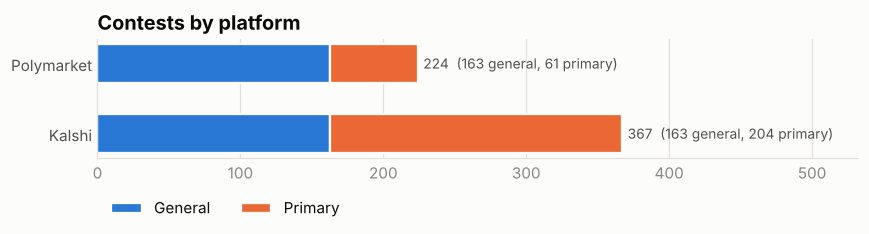

In [4]:
split = contests.groupby(["platform", "kind"]).size().unstack(fill_value=0).reindex(columns=["General", "Primary"])
fig, ax = plt.subplots(figsize=(8, 2.4))
y = np.arange(len(split))
ax.barh(y, split["General"], height=0.55, color=GENERAL, label="General", edgecolor=SURFACE, linewidth=1.5)
ax.barh(y, split["Primary"], left=split["General"], height=0.55, color=PRIMARY, label="Primary",
        edgecolor=SURFACE, linewidth=1.5)
for i, (platform, row) in enumerate(split.iterrows()):
    ax.text(row.sum() + 4, i, f"{row.sum()}  ({row['General']} general, {row['Primary']} primary)",
            va="center", fontsize=9, color=INK_2)
ax.set_yticks(y, split.index)
ax.set_xlim(0, split.sum(axis=1).max() * 1.45)
ax.set_title("Contests by platform")
ax.legend(loc="upper left", bbox_to_anchor=(0, -0.22), ncols=2)
value_grid(ax)
fig.tight_layout()
save(fig, "both_platforms")

## Where the US contests are

In [5]:
TILES = {  # (column, row) on a tile-grid map, row 0 at the top
    "AK": (0, 0), "ME": (11, 0), "VT": (10, 1), "NH": (11, 1),
    "WA": (1, 2), "ID": (2, 2), "MT": (3, 2), "ND": (4, 2), "MN": (5, 2), "IL": (6, 2), "WI": (7, 2),
    "MI": (8, 2), "NY": (9, 2), "RI": (10, 2), "MA": (11, 2),
    "OR": (1, 3), "NV": (2, 3), "WY": (3, 3), "SD": (4, 3), "IA": (5, 3), "IN": (6, 3), "OH": (7, 3),
    "PA": (8, 3), "NJ": (9, 3), "CT": (10, 3),
    "CA": (1, 4), "UT": (2, 4), "CO": (3, 4), "NE": (4, 4), "MO": (5, 4), "KY": (6, 4), "WV": (7, 4),
    "VA": (8, 4), "MD": (9, 4), "DE": (10, 4),
    "AZ": (2, 5), "NM": (3, 5), "KS": (4, 5), "AR": (5, 5), "TN": (6, 5), "NC": (7, 5), "SC": (8, 5),
    "DC": (9, 5),
    "OK": (4, 6), "LA": (5, 6), "MS": (6, 6), "AL": (7, 6), "GA": (8, 6),
    "HI": (0, 7), "TX": (4, 7), "FL": (9, 7),
}


def us_maps(df, label, name):
    df = df[df["country"] == "United States"]
    counts = df.groupby(["kind", "state"]).size()
    top = counts.max()
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
    for ax, kind in zip(axes, ["General", "Primary"]):
        for state, (col, row) in TILES.items():
            n = counts.get((kind, state), 0)
            dark = n and n / top > 0.45
            ax.add_patch(plt.Rectangle((col, -row), 0.92, 0.92, color=BLUES(n / top) if n else EMPTY_TILE, linewidth=0))
            ax.text(col + 0.46, -row + 0.60, state, ha="center", va="center", fontsize=8, color="white" if dark else INK_2)
            if n:
                ax.text(col + 0.46, -row + 0.30, str(n), ha="center", va="center", fontsize=9, weight="bold",
                        color="white" if dark else INK)
        total = counts.get(kind, pd.Series(dtype=int)).sum()
        ax.set_title(f"{label} · {kind.lower()} elections · {total} contests", fontsize=12)
        ax.set_xlim(-0.1, 12.1); ax.set_ylim(-7.2, 1.0); ax.set_aspect("equal"); ax.axis("off")
    national = (df["state"] == "national").sum()
    if national:
        fig.text(0.01, 0.01, f"Plus {national} national contest(s), not shown on the map.", fontsize=9, color=MUTED)
    fig.tight_layout()
    save(fig, name)

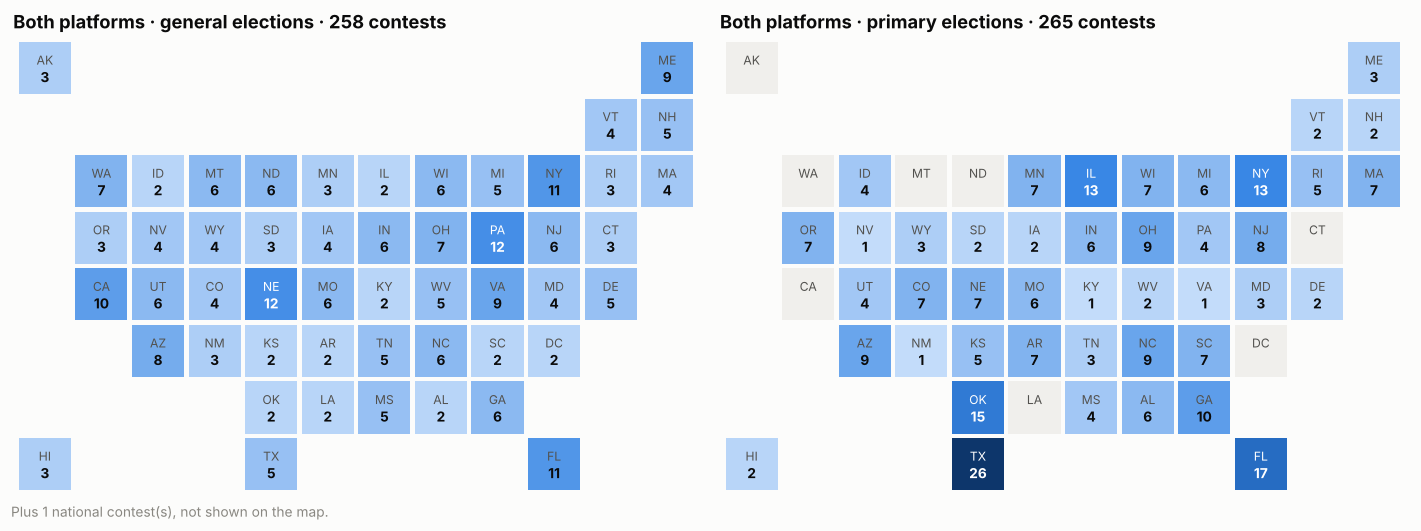

In [6]:
us_maps(PLATFORMS["Both platforms"], "Both platforms", "both_us_map")

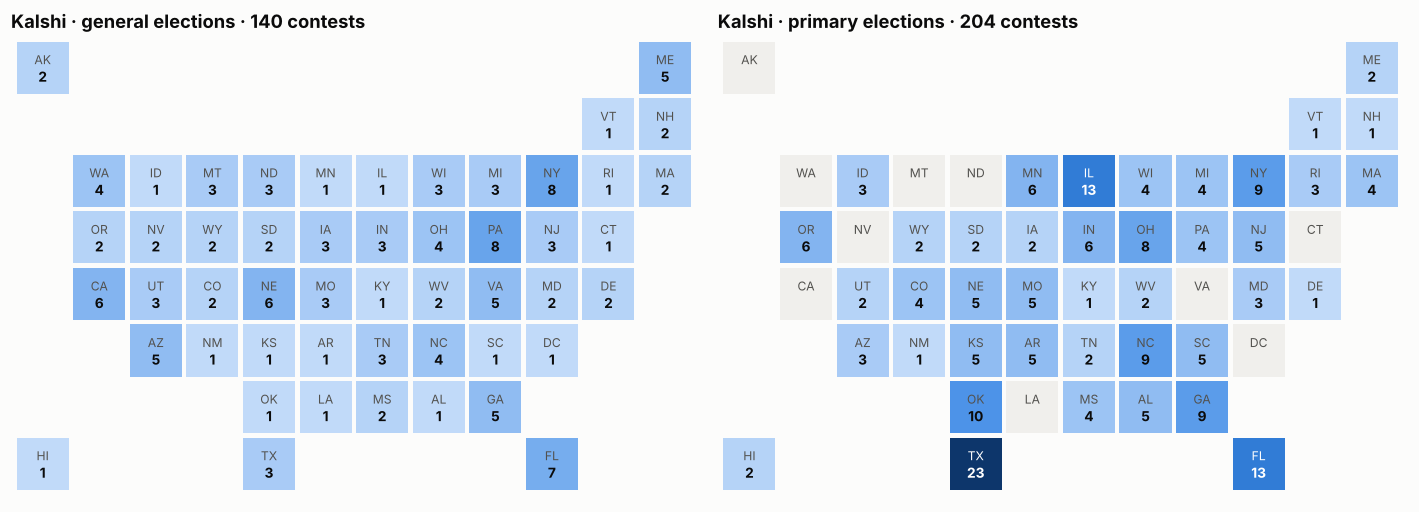

In [7]:
us_maps(PLATFORMS["Kalshi"], "Kalshi", "kalshi_us_map")

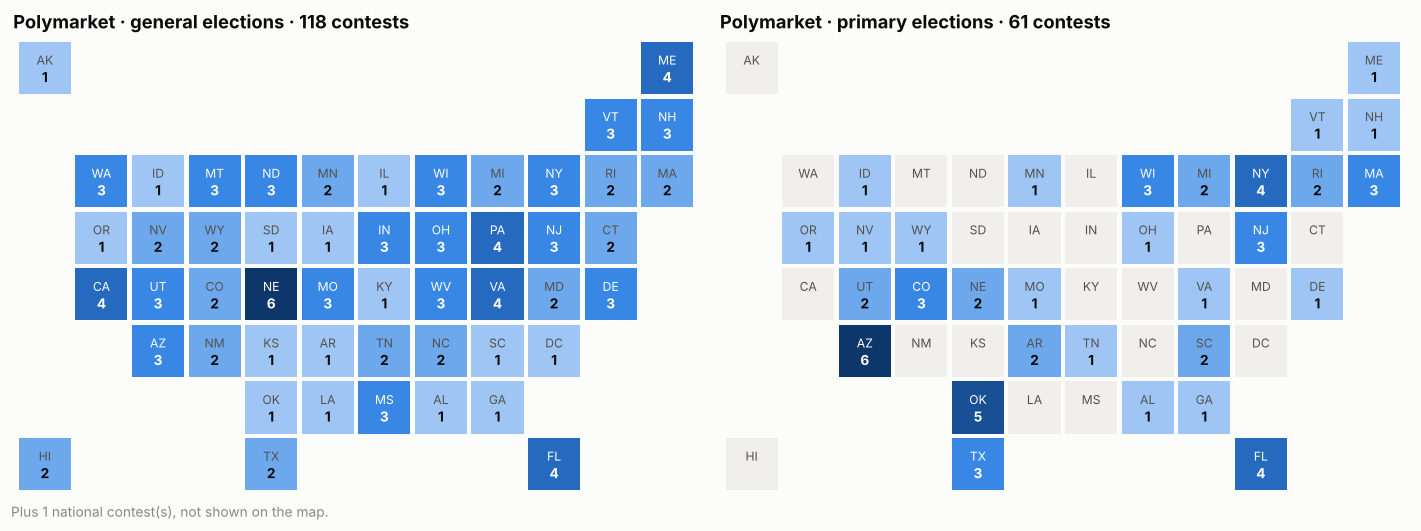

In [8]:
us_maps(PLATFORMS["Polymarket"], "Polymarket", "polymarket_us_map")

## By country

In [9]:
def stacked_bars(table, title, name, height=None, label_split=True):
    table = table.reindex(columns=["General", "Primary"], fill_value=0)
    table = table.loc[table.sum(axis=1).sort_values().index]
    fig, ax = plt.subplots(figsize=(9, height or max(2.4, 0.42 * len(table) + 1.2)))
    y = np.arange(len(table))
    ax.barh(y, table["General"], height=0.6, color=GENERAL, label="General", edgecolor=SURFACE, linewidth=1.5)
    ax.barh(y, table["Primary"], left=table["General"], height=0.6, color=PRIMARY, label="Primary",
            edgecolor=SURFACE, linewidth=1.5)
    for i, (_, row) in enumerate(table.iterrows()):
        total = row.sum()
        text = f"{total}  ({row['General']} general, {row['Primary']} primary)" if label_split and row["Primary"] and row["General"] else str(total)
        ax.text(total + table.sum(axis=1).max() * 0.01, i, text, va="center", fontsize=9, color=INK_2)
    ax.set_yticks(y, table.index)
    ax.set_xlim(0, table.sum(axis=1).max() * 1.4)
    ax.set_title(title)
    ax.legend(loc="lower right", ncols=2)
    value_grid(ax)
    fig.tight_layout()
    save(fig, name)


def by_country(df, label, name):
    table = df.groupby(["country", "kind"]).size().unstack(fill_value=0)
    outside = table.drop("United States", errors="ignore").sum().sum()
    countries = len(table) - ("United States" in table.index)
    stacked_bars(table, f"{label} · contests by country · {outside} outside the US, in {countries} countries", name)

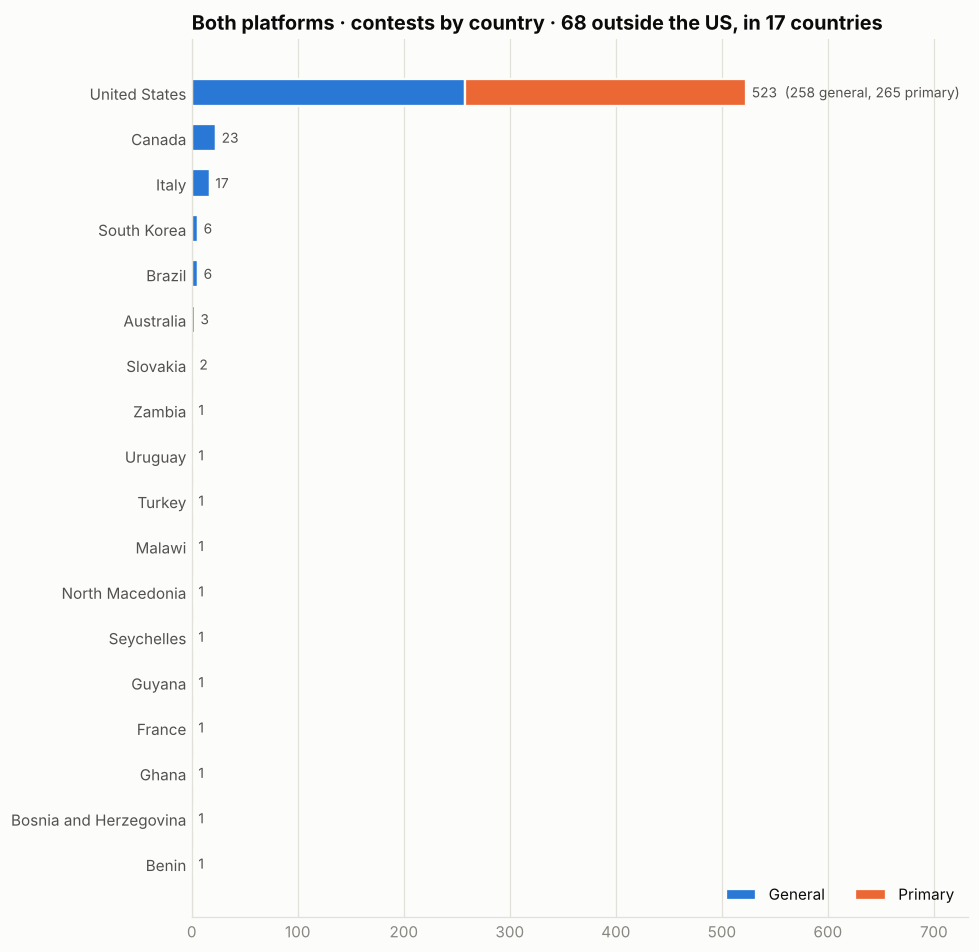

In [10]:
by_country(PLATFORMS["Both platforms"], "Both platforms", "both_by_country")

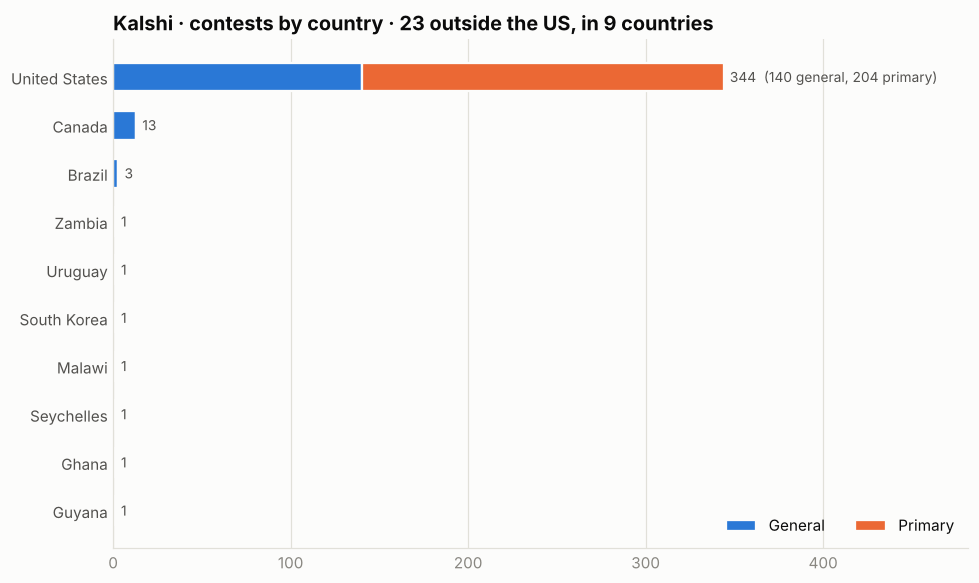

In [11]:
by_country(PLATFORMS["Kalshi"], "Kalshi", "kalshi_by_country")

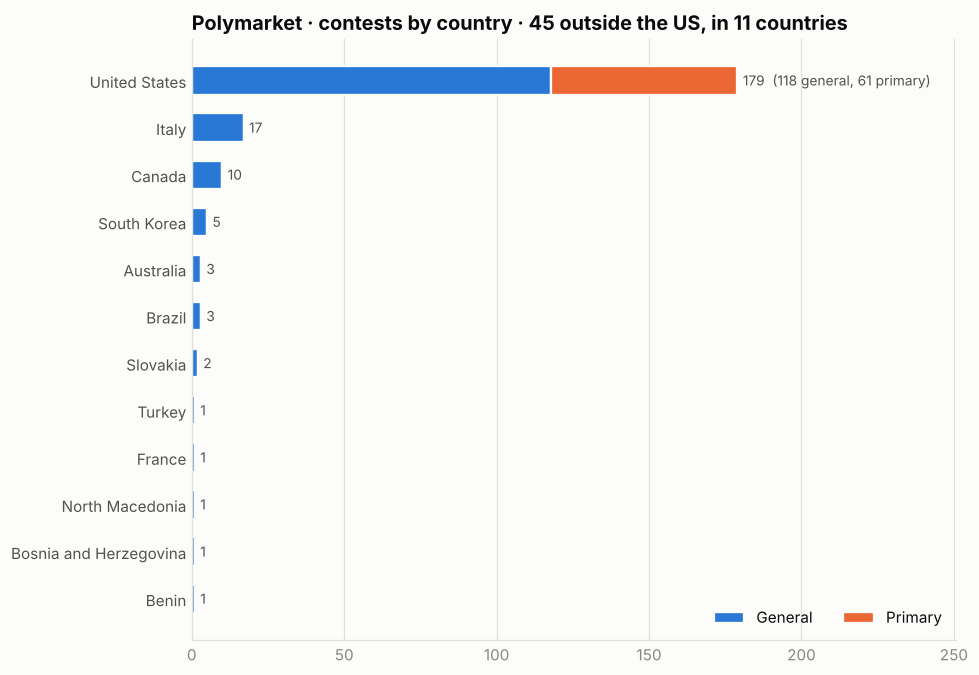

In [12]:
by_country(PLATFORMS["Polymarket"], "Polymarket", "polymarket_by_country")

## By office (US)

In [13]:
def by_office(df, label, name):
    table = df[df["country"] == "United States"].groupby(["office", "kind"]).size().unstack(fill_value=0)
    stacked_bars(table, f"{label} · US contests by office", name, label_split=False)

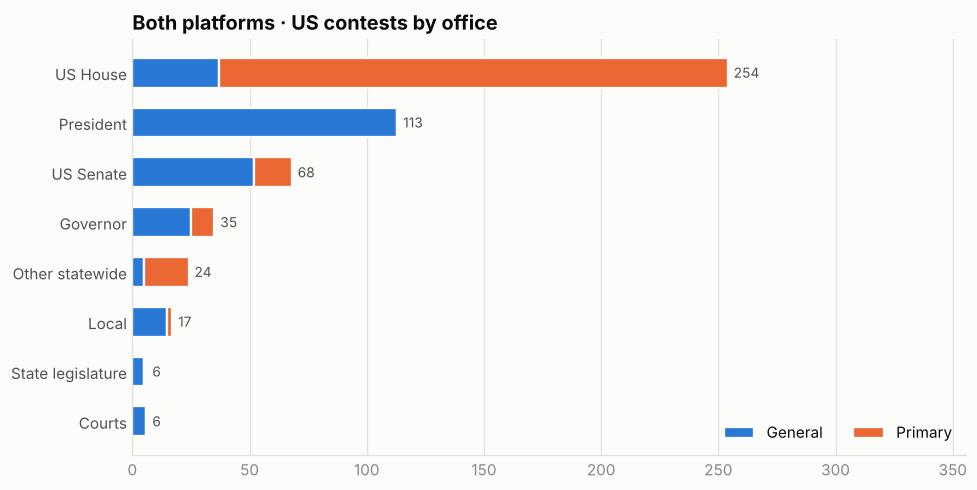

In [14]:
by_office(PLATFORMS["Both platforms"], "Both platforms", "both_by_office")

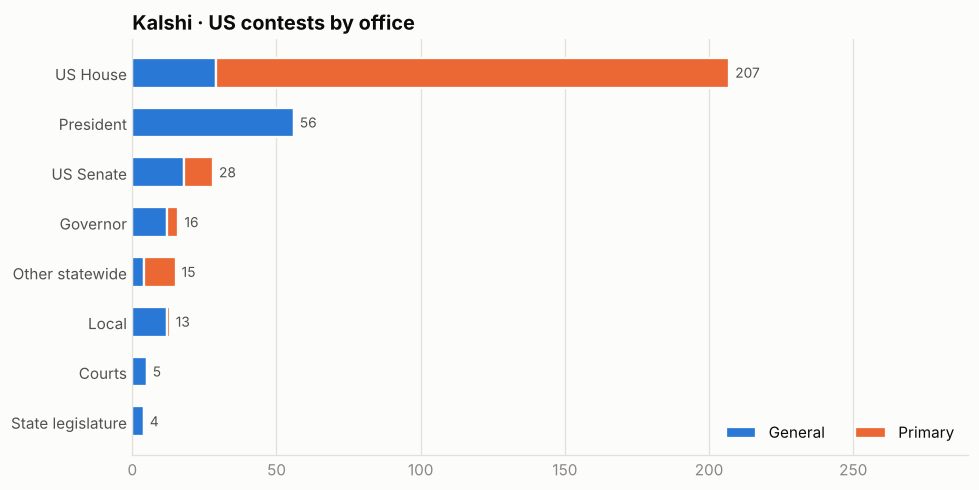

In [15]:
by_office(PLATFORMS["Kalshi"], "Kalshi", "kalshi_by_office")

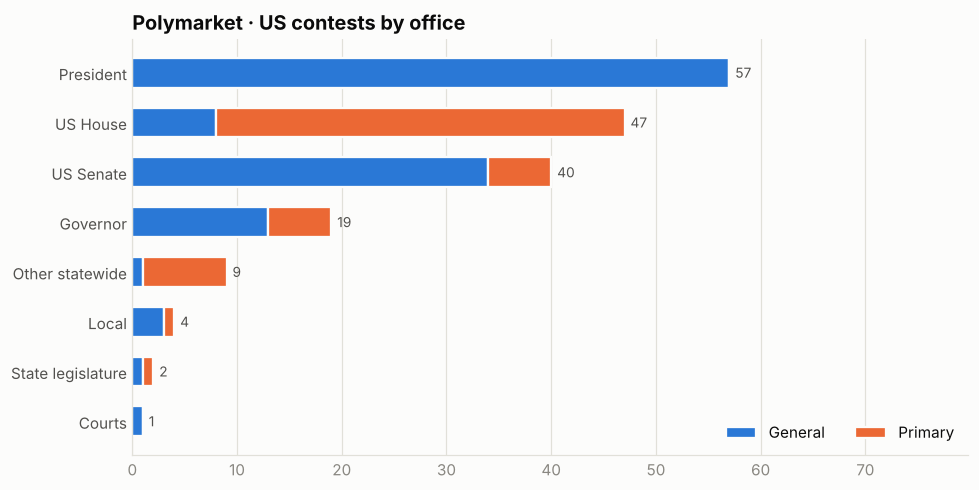

In [16]:
by_office(PLATFORMS["Polymarket"], "Polymarket", "polymarket_by_office")

## When they were decided

In [17]:
def by_month(df, label, name):
    months = pd.period_range(min(pd.Period("2024-10", "M"), contests["decided"].min()), contests["decided"].max(), freq="M")
    table = (df.groupby(["decided", "kind"]).size().unstack(fill_value=0)
             .reindex(index=months, columns=["General", "Primary"], fill_value=0))
    fig, ax = plt.subplots(figsize=(11, 3.8))
    x = np.arange(len(table))
    ax.bar(x, table["General"], width=0.7, color=GENERAL, label="General", edgecolor=SURFACE, linewidth=1.5)
    ax.bar(x, table["Primary"], bottom=table["General"], width=0.7, color=PRIMARY, label="Primary",
           edgecolor=SURFACE, linewidth=1.5)
    totals = table.sum(axis=1)
    for i, total in enumerate(totals):
        if total >= max(10, totals.max() * 0.08):
            ax.text(i, total + totals.max() * 0.02, str(total), ha="center", fontsize=9, color=INK_2)
    ax.set_xticks(x, [m.strftime("%b\n%Y") if m.month in (1, 7) or i == 0 else m.strftime("%b")
                      for i, m in enumerate(table.index)], fontsize=8)
    ax.set_ylim(0, totals.max() * 1.15)
    ax.set_title(f"{label} · contests by month decided")
    ax.legend(loc="upper right", ncols=2)
    value_grid(ax, "y")
    fig.tight_layout()
    save(fig, name)

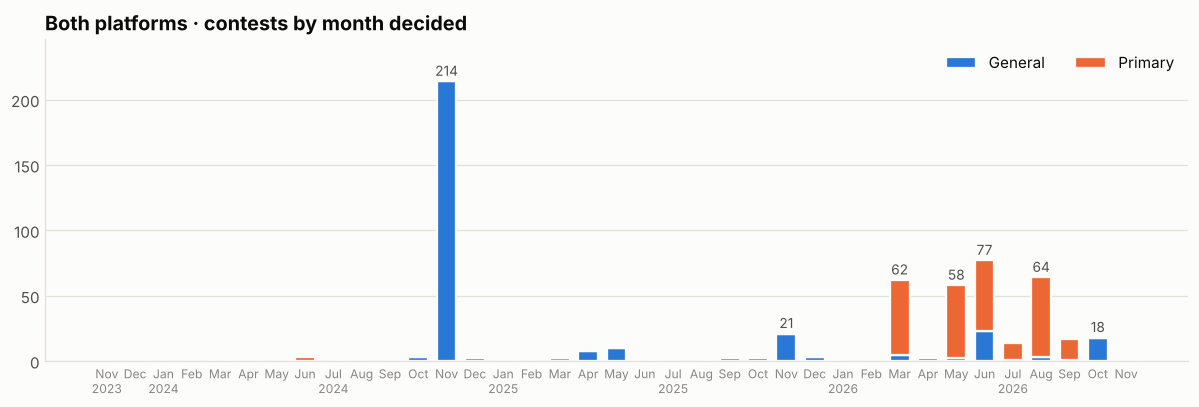

In [18]:
by_month(PLATFORMS["Both platforms"], "Both platforms", "both_by_month")

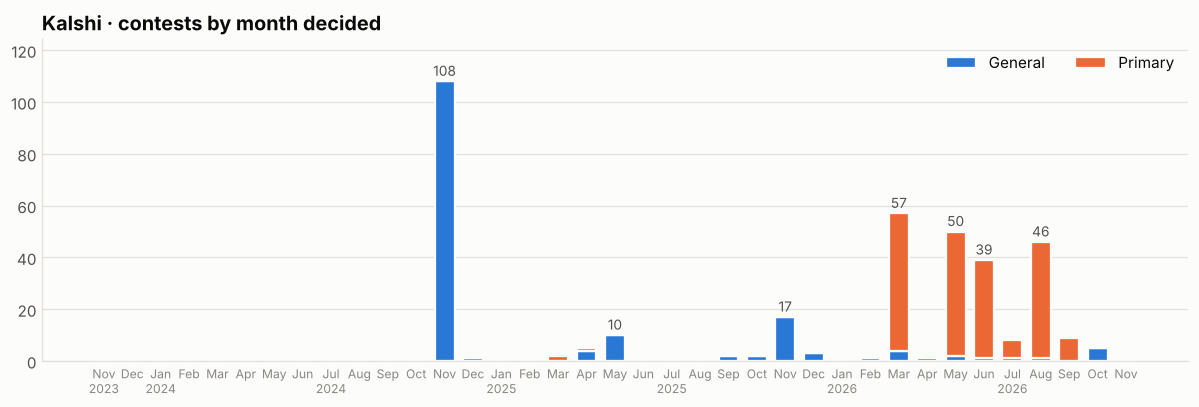

In [19]:
by_month(PLATFORMS["Kalshi"], "Kalshi", "kalshi_by_month")

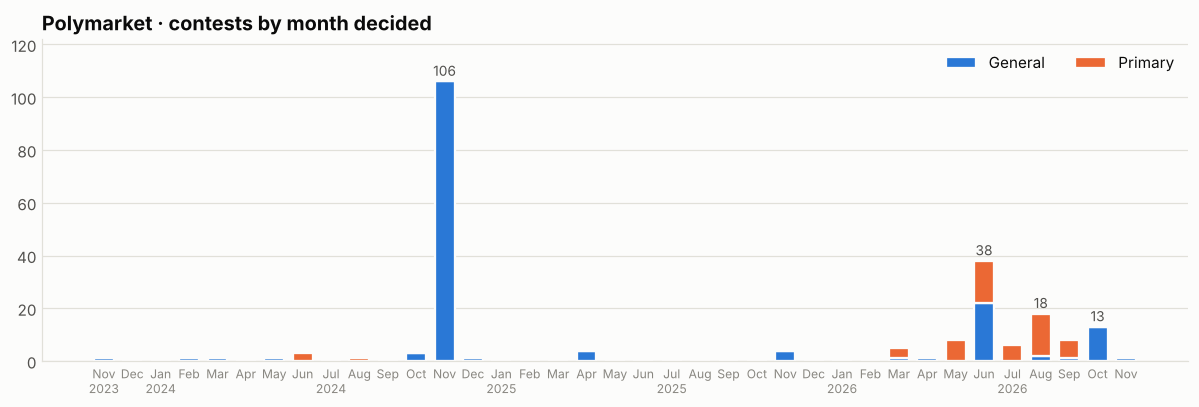

In [20]:
by_month(PLATFORMS["Polymarket"], "Polymarket", "polymarket_by_month")

## How much they traded

Units differ, so the platforms are never on one axis: Kalshi counts contracts, Polymarket reports dollars, and
Polymarket's figure includes wash trading. Polymarket volume excludes the "Other" market.

In [21]:
def volume(df, label, unit, name):
    low, high = np.log10(df["volume"].clip(lower=1).min()) - 0.1, np.log10(df["volume"].max()) + 0.1
    bins = np.logspace(low, high, 30)
    fig, axes = plt.subplots(2, 1, figsize=(9, 4.6), sharex=True)
    for ax, kind, colour in zip(axes, ["General", "Primary"], [GENERAL, PRIMARY]):
        values = df.loc[df["kind"] == kind, "volume"].clip(lower=1)
        ax.hist(values, bins=bins, color=colour, edgecolor=SURFACE, linewidth=1.5)
        median = values.median()
        ax.axvline(median, color=INK_2, linewidth=1)
        ax.set_title(f"{kind} · {len(values)} contests · median {compact(median)} {unit} (line)", fontsize=11)
        value_grid(ax, "y")
    axes[1].set_xscale("log")
    axes[1].xaxis.set_major_formatter(FuncFormatter(compact))
    axes[1].set_xlabel(f"{unit.capitalize()} traded per contest (log scale)")
    fig.suptitle(f"{label} · trading volume", x=0.01, ha="left", fontsize=13, weight="bold")
    fig.tight_layout()
    save(fig, name)

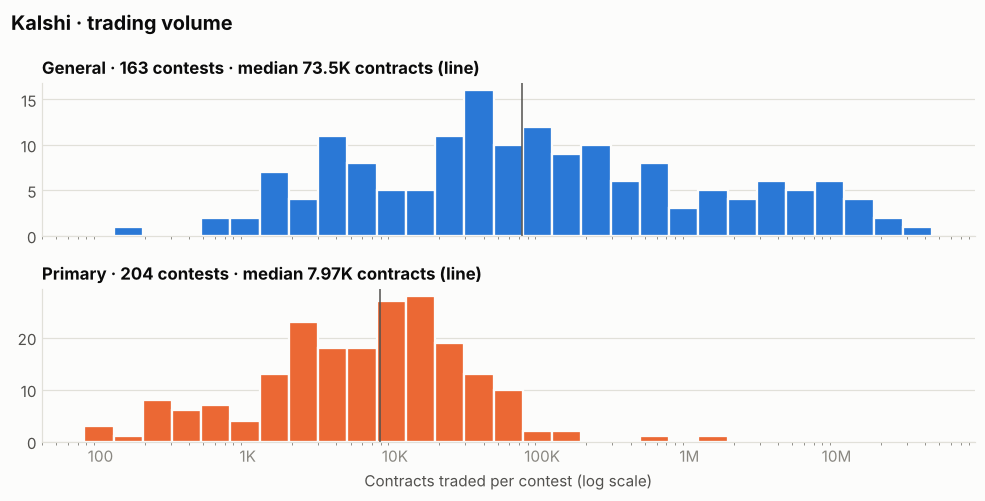

In [22]:
volume(PLATFORMS["Kalshi"], "Kalshi", "contracts", "kalshi_volume")

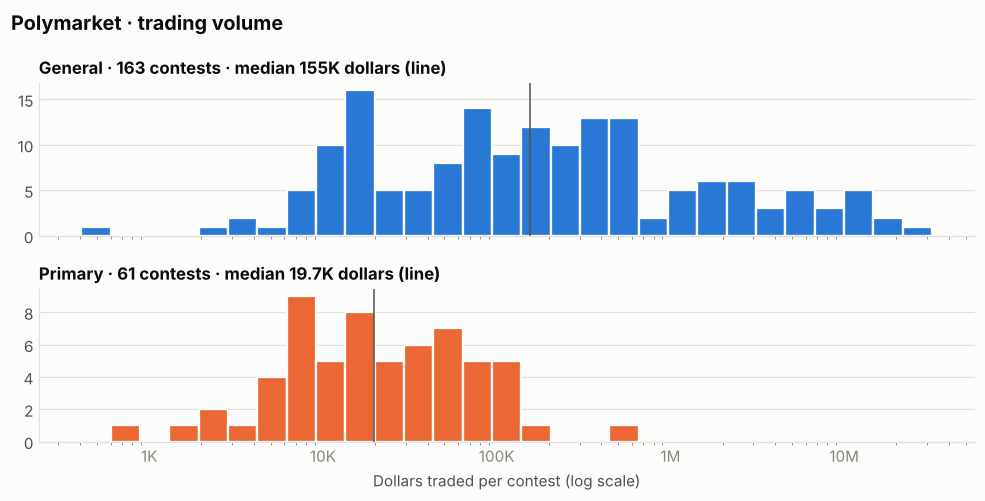

In [23]:
volume(PLATFORMS["Polymarket"], "Polymarket", "dollars", "polymarket_volume")

## Table

In [24]:
table = (contests.groupby(["platform", "country", "kind"])
         .agg(contests=("contest_id", "size"), median_volume=("volume", "median")).round(0))
table.to_csv(FIGURES / "summary.csv")
table

contests  median_volume
platform   country                kind                            
Kalshi     Brazil                 General         3        14588.0
           Canada                 General        13         3093.0
           Ghana                  General         1         8561.0
           Guyana                 General         1         4362.0
           Malawi                 General         1        51738.0
           Seychelles             General         1       129483.0
           South Korea            General         1         7031.0
           United States          General       140       113318.0
                                  Primary       204         7973.0
           Uruguay                General         1        56430.0
           Zambia                 General         1        19833.0
Polymarket Australia              General         3        16834.0
           Benin                  General         1        36599.0
           Bosnia and Herzegovina General         1         4643.0
           Brazil                 General         3        47595.0
           Canada                 General        10        12472.0
           France                 General         1       304548.0
           Italy                  General        17        15248.0
           North Macedonia        General         1        16135.0
           Slovakia               General         2        17627.0
           South Korea            General         5        43833.0
           Turkey                 General         1        43566.0
           United States          General       118       335524.0
                                  Primary        61        19687.0